# Diabetes Risk Prediction (Low / Moderate / High)
Models: Logistic Regression and Random Forest. Metrics: Accuracy, Precision, Recall, F1, RMSE, ROC-AUC.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, roc_auc_score, confusion_matrix, classification_report, roc_curve)
from sklearn.preprocessing import label_binarize
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RS = 42

## 1. Load data

In [2]:
import os
for p in ["diabetes_risk.csv", "data/diabetes_risk.csv", "Diabetes_Risk_Prediction_Dataset/diabetes_risk.csv"]:
    if os.path.exists(p): break
else:
    raise FileNotFoundError("Put diabetes_risk.csv (from the dataset zip) in the same folder as this notebook.")
df = pd.read_csv(p)
print(df.shape); print(df.isna().sum()[df.isna().sum() > 0]); print("Duplicates:", df.duplicated().sum())
LABELS = ["Low", "Moderate", "High"]          # ordinal order 0,1,2
y = df["diabetes_risk"].map({l: i for i, l in enumerate(LABELS)})
X = df.drop(columns=["diabetes_risk", "patient_id"])   # patient_id is only an identifier

(15000, 19)
smoking_status          472
alcohol_consumption    3788
income_bracket          463
dtype: int64
Duplicates: 0


## 2. Visualisation (EDA)

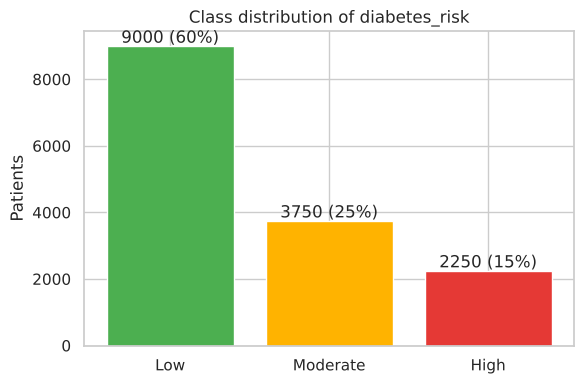

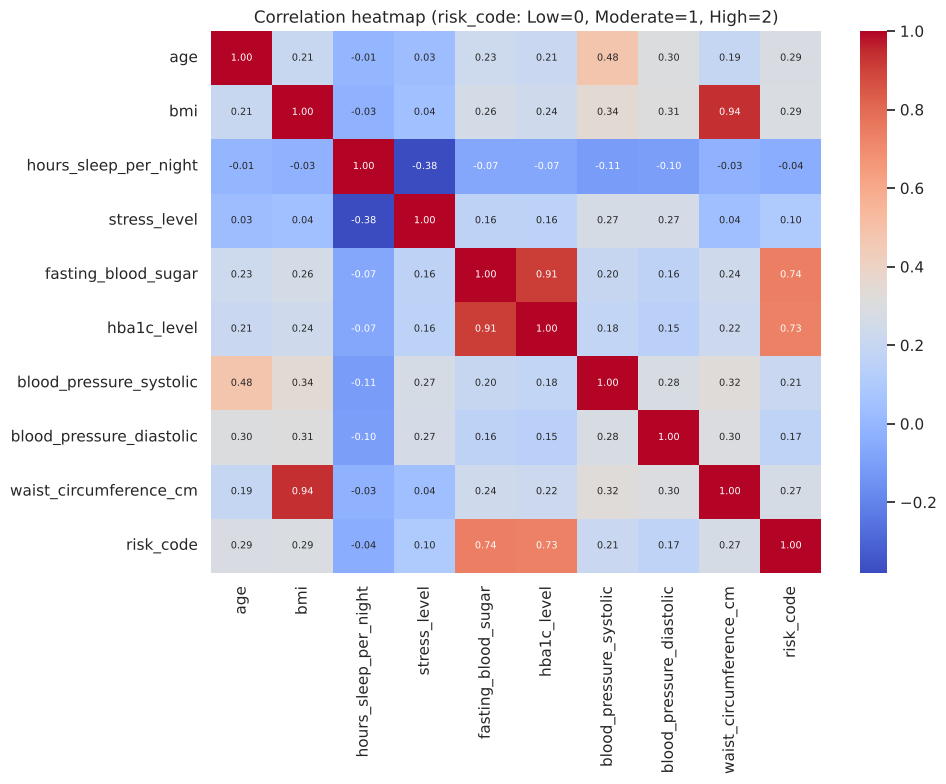

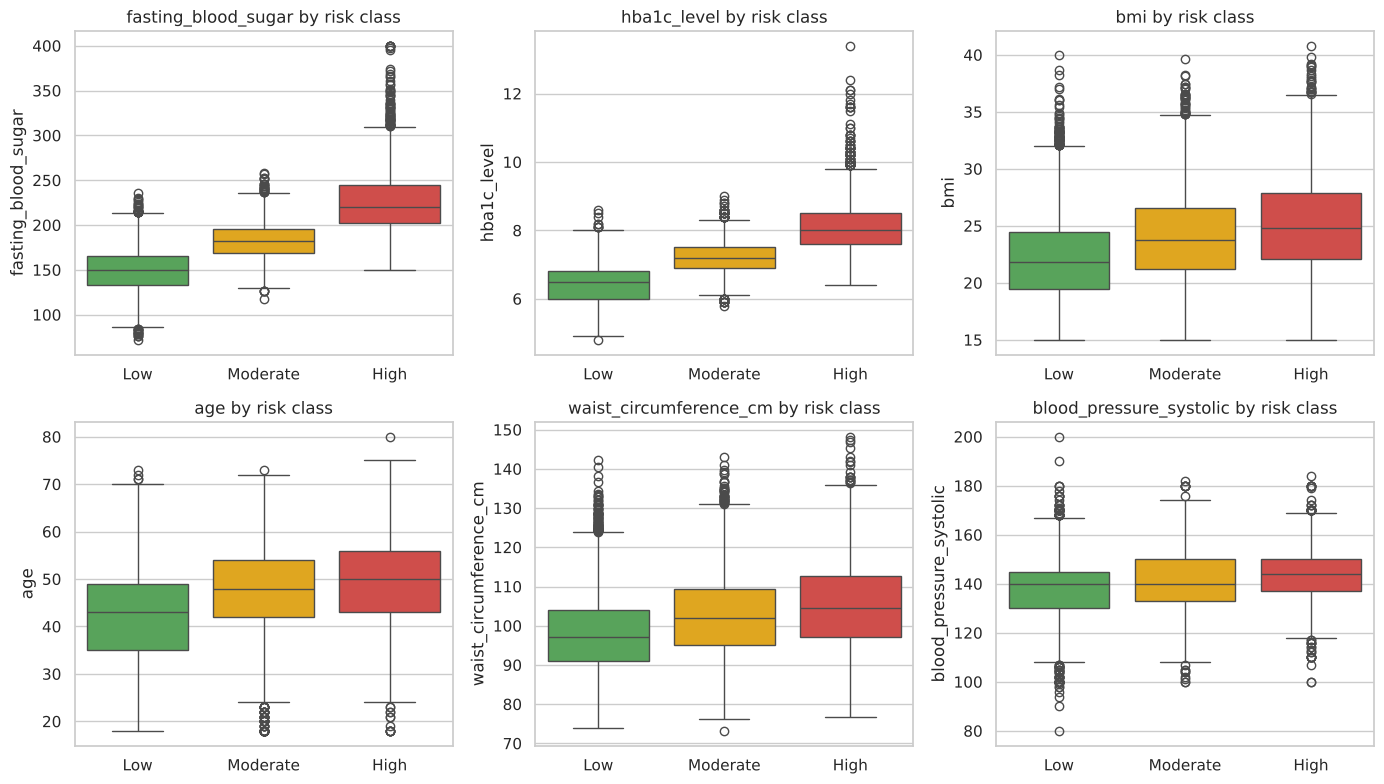

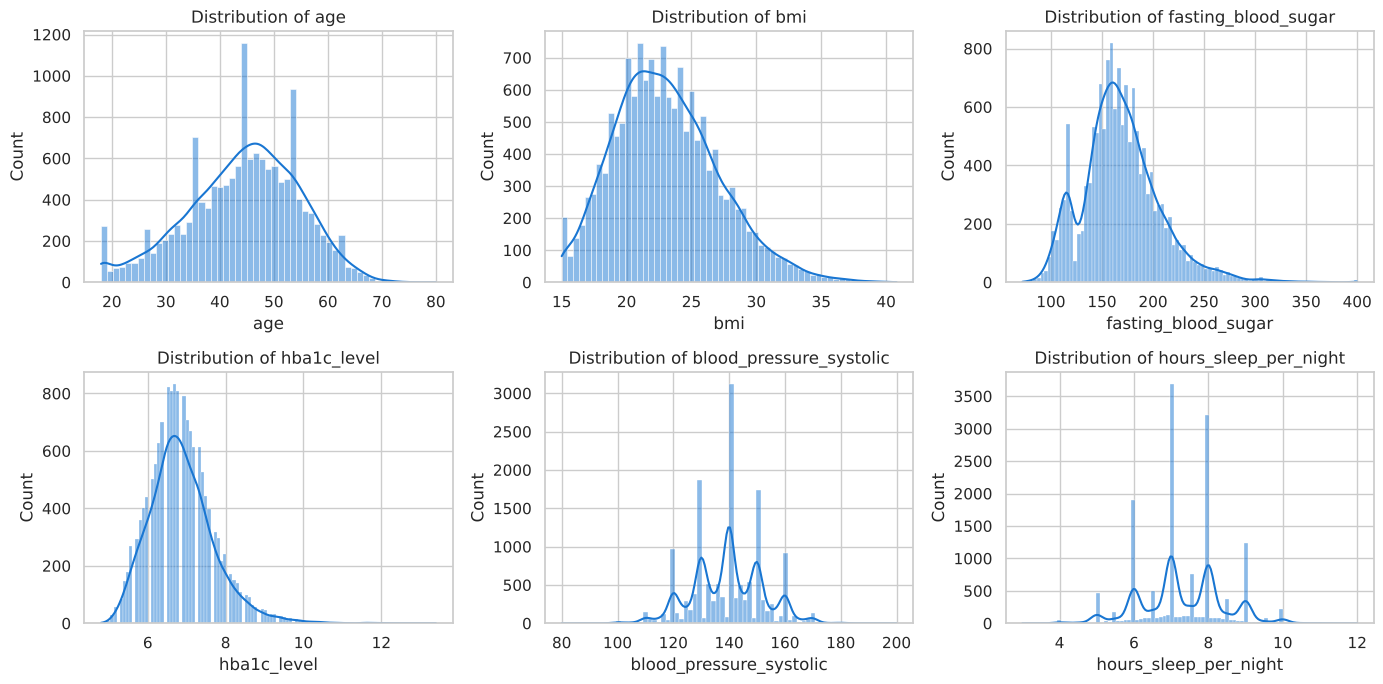

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
order = df["diabetes_risk"].value_counts().reindex(LABELS)
ax.bar(order.index, order.values, color=["#4caf50", "#ffb300", "#e53935"])
for i, v in enumerate(order.values): ax.text(i, v + 100, f"{v} ({v/len(df):.0%})", ha="center")
ax.set_title("Class distribution of diabetes_risk"); ax.set_ylabel("Patients")
plt.tight_layout(); plt.show()

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
corr = df[num_cols].assign(risk_code=y).corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation heatmap (risk_code: Low=0, Moderate=1, High=2)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.ravel(), ["fasting_blood_sugar", "hba1c_level", "bmi", "age", "waist_circumference_cm", "blood_pressure_systolic"]):
    sns.boxplot(data=df, x="diabetes_risk", y=c, order=LABELS, ax=ax, palette=["#4caf50", "#ffb300", "#e53935"])
    ax.set_title(c + " by risk class"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), ["age", "bmi", "fasting_blood_sugar", "hba1c_level", "blood_pressure_systolic", "hours_sleep_per_night"]):
    sns.histplot(df[c], kde=True, ax=ax, color="#1976d2"); ax.set_title("Distribution of " + c)
plt.tight_layout(); plt.show()

## 3. Preprocessing and split (80/20 stratified)
Numeric: median imputation + StandardScaler. Categorical: missing -> "Unknown" + one-hot encoding.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=3,
                                            class_weight="balanced", n_jobs=-1, random_state=RS),
}
pipes = {n: Pipeline([("pre", pre), ("clf", m)]) for n, m in models.items()}

## 4. Train and evaluate
RMSE is computed on the ordinal class codes (Low=0, Moderate=1, High=2): sqrt(mean((true-pred)^2)).

In [5]:
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
results, preds, probas = {}, {}, {}
for n, p in pipes.items():
    cv = cross_val_score(p, X_train, y_train, cv=skf, scoring="accuracy")
    p.fit(X_train, y_train)
    yp, pr = p.predict(X_test), p.predict_proba(X_test)
    preds[n], probas[n] = yp, pr
    yb = label_binarize(y_test, classes=[0, 1, 2])
    results[n] = {
        "cv_accuracy_mean": cv.mean(), "cv_accuracy_std": cv.std(),
        "train_accuracy": accuracy_score(y_train, p.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, yp),
        "precision_macro": precision_score(y_test, yp, average="macro"),
        "recall_macro": recall_score(y_test, yp, average="macro"),
        "f1_macro": f1_score(y_test, yp, average="macro"),
        "rmse": float(np.sqrt(mean_squared_error(y_test, yp))),
        "roc_auc_ovr": roc_auc_score(yb, pr, average="macro", multi_class="ovr"),
        "per_class_recall": dict(zip(LABELS, recall_score(y_test, yp, average=None).round(4).tolist())),
        "confusion_matrix": confusion_matrix(y_test, yp).tolist(),
        "report": classification_report(y_test, yp, target_names=LABELS, output_dict=True),
    }
    print(f"\n=== {n} ===\n", classification_report(y_test, yp, target_names=LABELS))
    print({k: round(v, 4) for k, v in results[n].items() if isinstance(v, float)})

best = max(results, key=lambda k: (results[k]["test_accuracy"], results[k]["f1_macro"]))
print("\nBEST MODEL:", best)


=== Logistic Regression ===
               precision    recall  f1-score   support

         Low       0.92      0.81      0.86      1800
    Moderate       0.54      0.68      0.60       750
        High       0.74      0.78      0.76       450

    accuracy                           0.77      3000
   macro avg       0.73      0.76      0.74      3000
weighted avg       0.80      0.77      0.78      3000

{'cv_accuracy_mean': np.float64(0.7675), 'cv_accuracy_std': np.float64(0.0029), 'train_accuracy': 0.7724, 'test_accuracy': 0.7717, 'precision_macro': 0.7337, 'recall_macro': 0.7567, 'f1_macro': 0.741, 'rmse': 0.4913, 'roc_auc_ovr': 0.9111}



=== Random Forest ===
               precision    recall  f1-score   support

         Low       0.92      0.80      0.85      1800
    Moderate       0.53      0.71      0.61       750
        High       0.77      0.74      0.76       450

    accuracy                           0.77      3000
   macro avg       0.74      0.75      0.74      3000
weighted avg       0.80      0.77      0.78      3000

{'cv_accuracy_mean': np.float64(0.7679), 'cv_accuracy_std': np.float64(0.0057), 'train_accuracy': 0.8668, 'test_accuracy': 0.769, 'precision_macro': 0.7417, 'recall_macro': 0.7507, 'f1_macro': 0.7407, 'rmse': 0.493, 'roc_auc_ovr': 0.9098}

BEST MODEL: Logistic Regression


## 5. Result visualisations

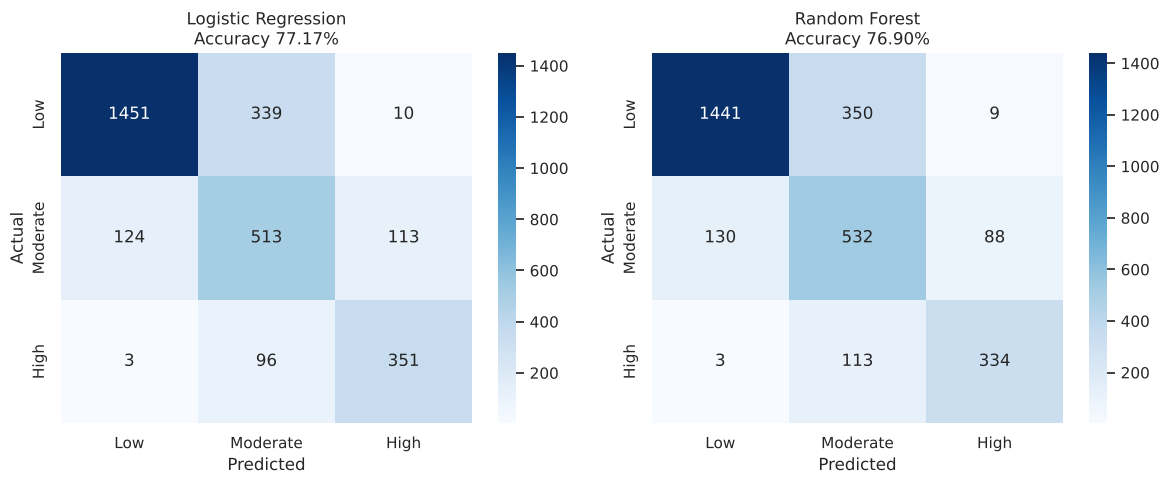

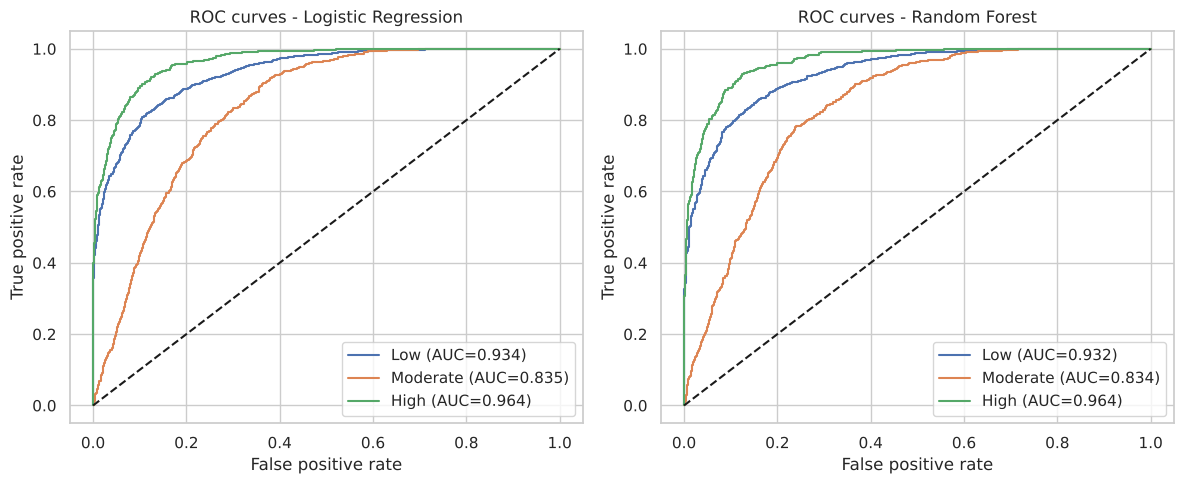

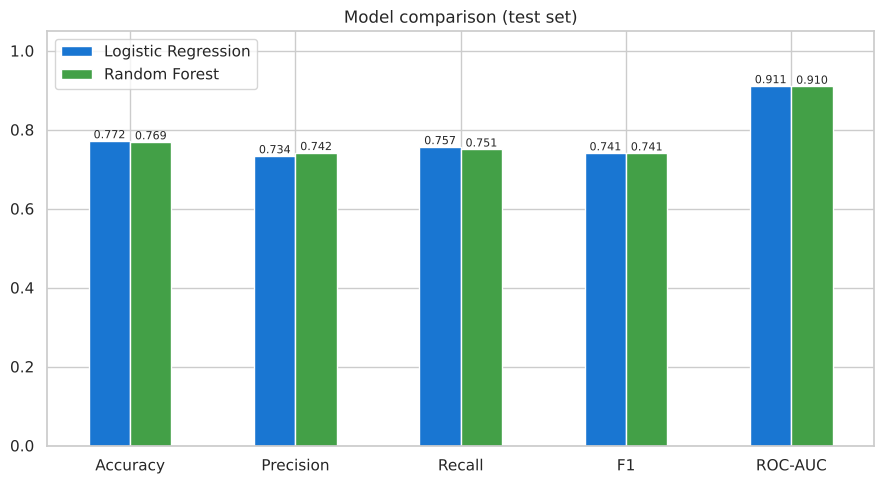

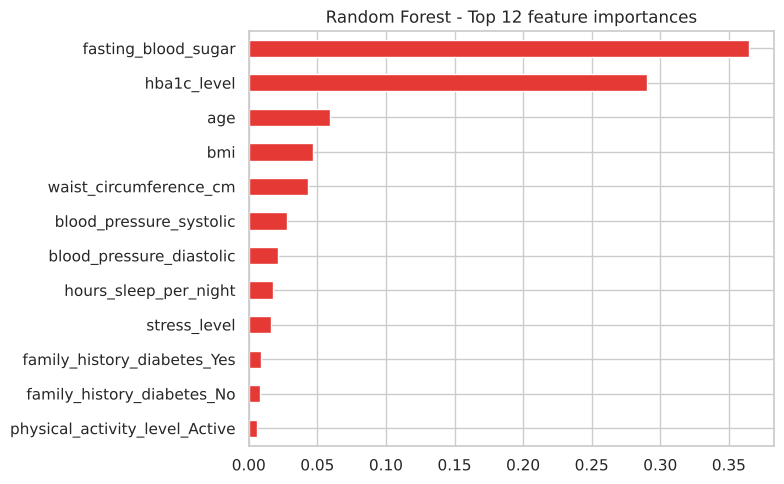

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n in zip(axes, pipes):
    sns.heatmap(confusion_matrix(y_test, preds[n]), annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(f"{n}\nAccuracy {results[n]['test_accuracy']:.2%}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5)); yb = label_binarize(y_test, classes=[0, 1, 2])
for ax, n in zip(axes, pipes):
    for i, l in enumerate(LABELS):
        f, t, _ = roc_curve(yb[:, i], probas[n][:, i]); ax.plot(f, t, label=f"{l} (AUC={roc_auc_score(yb[:, i], probas[n][:, i]):.3f})")
    ax.plot([0, 1], [0, 1], "k--"); ax.set_title(f"ROC curves - {n}"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend()
plt.tight_layout(); plt.show()

mn = ["test_accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr"]
cmp = pd.DataFrame({n: [results[n][m] for m in mn] for n in pipes}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
ax = cmp.plot(kind="bar", figsize=(9, 5), color=["#1976d2", "#43a047"]); ax.set_ylim(0, 1.05); ax.set_title("Model comparison (test set)")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# feature importance (best model + RF)
feat = pipes[best].named_steps["pre"].get_feature_names_out()
rf = pipes["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=[f.split("__")[1] for f in feat]).sort_values(ascending=False)
imp.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="#e53935"); plt.title("Random Forest - Top 12 feature importances")
plt.tight_layout(); plt.show()
lr = pipes["Logistic Regression"].named_steps["clf"]
coef = pd.Series(np.abs(lr.coef_).mean(0), index=[f.split("__")[1] for f in feat]).sort_values(ascending=False)

## 6. Final model: use the most accurate one
The model with the highest test accuracy (Logistic Regression here) is selected and used to predict risk for new patients.

In [7]:
final = pipes[best]
print("Selected model:", best, "| test accuracy:", round(results[best]["test_accuracy"], 4), "| RMSE:", round(results[best]["rmse"], 4))
sample = X_test.iloc[:5].copy()
proba = final.predict_proba(sample)
out = sample[["age", "bmi", "fasting_blood_sugar", "hba1c_level"]].copy()
out["actual"] = [LABELS[i] for i in y_test.iloc[:5]]
out["predicted"] = [LABELS[i] for i in final.predict(sample)]
for i, l in enumerate(LABELS): out["P(" + l + ")"] = proba[:, i].round(3)
display(out)

Selected model: Logistic Regression | test accuracy: 0.7717 | RMSE: 0.4913


,age,bmi,fasting_blood_sugar,hba1c_level,actual,predicted,P(Low),P(Moderate),P(High)
3642,43,24.8,146,6.3,Low,Low,0.911,0.089,0.000
10987,52,19.0,172,7.1,Low,Moderate,0.432,0.536,0.033
13639,58,24.4,229,8.1,High,High,0.000,0.068,0.931
57,65,26.1,191,7.2,Low,High,0.011,0.407,0.582
2513,48,22.7,155,6.2,Moderate,Low,0.889,0.111,0.000


## 7. Conclusion
- Two models were trained and compared on the same 80/20 split; both were checked with 5-fold cross-validation.
- Logistic Regression and Random Forest perform almost identically; the most accurate (Logistic Regression) is used as the final model.
- Accuracy stays near 77% because the risk label contains random noise and the Moderate class is hard to separate; Low-vs-High mistakes are very rare.
- Blood sugar measures (fasting blood sugar, HbA1c) are the strongest predictors, followed by age and BMI.